In [1]:
!pip install kagglehub


  Attempting uninstall: certifi

    Found existing installation: certifi 2025.8.3

    Uninstalling certifi-2025.8.3:

      Successfully uninstalled certifi-2025.8.3

   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   -------------------------- ------------- 2/3 [kagglehub]
   ---------------------------------------- 3/3 [kagglehub]



In [3]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("ritwikb3/heart-disease-statlog")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\siiri\.cache\kagglehub\datasets\ritwikb3\heart-disease-statlog\versions\1


In [6]:
import os
import pandas as pd

# 1. Tarkistetaan kansion tiedostot
path = r"C:\Users\siiri\.cache\kagglehub\datasets\ritwikb3\heart-disease-statlog\versions\1"
print("Kansion tiedostot:", os.listdir(path))

Kansion tiedostot: ['Heart_disease_statlog.csv']


In [8]:
# 2. Avataan data Pandas-taulukoksi
df = pd.read_csv(f"{path}/Heart_disease_statlog.csv")

# 3. Tarkistetaan miltä data näyttää
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0


In [9]:
print(df.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [13]:
# Luodaan sanakirja vanhoista ja uutta nimistä
new_column_names = {
    'age': 'age',
    'sex': 'sex',
    'cp': 'chest_pain_type',
    'trestbps': 'resting_blood_pressure',
    'chol': 'cholesterol',
    'fbs': 'fasting_blood_sugar',
    'restecg': 'resting_ecg',
    'thalach': 'max_heart_rate',
    'exang': 'exercise_angina',
    'oldpeak': 'st_depression',
    'slope': 'st_slope',
    'ca': 'major_vessels',
    'thal': 'thalassemia',
    'target': 'heart_disease'
}

# Päivitetään sarakkeiden nimet
df = df.rename(columns=new_column_names)

# Tarkistetaan uudet sarakkeiden nimet
print(df.columns)

Index(['age', 'sex', 'chest_pain_type', 'resting_blood_pressure',
       'cholesterol', 'fasting_blood_sugar', 'resting_ecg', 'max_heart_rate',
       'exercise_angina', 'st_depression', 'st_slope', 'major_vessels',
       'thalassemia', 'heart_disease'],
      dtype='object')


In [14]:
df.head()


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,major_vessels,thalassemia,heart_disease
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0


In [15]:
# Muutetaan sukupuoli: 1 -> male, 0 -> female
df['sex'] = df['sex'].map({1: 'male', 0: 'female'})

# Muutetaan sairaustieto (target): 1 -> yes, 0 -> no
df['heart_disease_label'] = df['heart_disease'].map({1: 'yes', 0: 'no'})

# Katsotaan miltä ensimmäiset rivit näyttävät nyt
df[['age', 'sex', 'cholesterol', 'heart_disease_label']].head()

,age,sex,cholesterol,heart_disease_label
0,70,male,322,yes
1,67,female,564,no
2,57,male,261,yes
3,64,male,263,no
4,74,female,269,no


In [16]:
df.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,major_vessels,thalassemia,heart_disease,heart_disease_label
0,70,male,3,130,322,0,2,109,0,2.4,1,3,1,1,yes
1,67,female,2,115,564,0,2,160,0,1.6,1,0,3,0,no
2,57,male,1,124,261,0,0,141,0,0.3,0,0,3,1,yes
3,64,male,3,128,263,0,0,105,1,0.2,1,1,3,0,no
4,74,female,1,120,269,0,2,121,1,0.2,0,1,1,0,no


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

In [ ]:
# How does age affect on the risk in heart diseases?


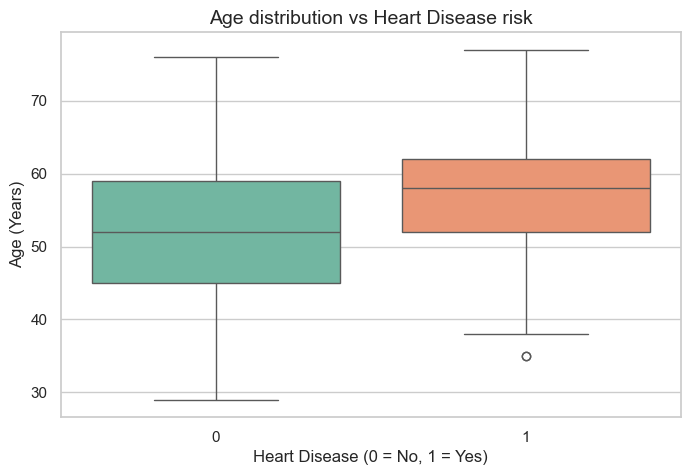

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='heart_disease', y='age', data=df, hue='heart_disease', palette='Set2', legend=False)

plt.title('Age distribution vs Heart Disease risk', fontsize=14)
plt.xlabel('Heart Disease (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Age (Years)', fontsize=12)
plt.show()


In [ ]:
# older people have higher risk at having a heart disease or having it already 

In [ ]:
# Does having high colesterol risk having a heart disease? 

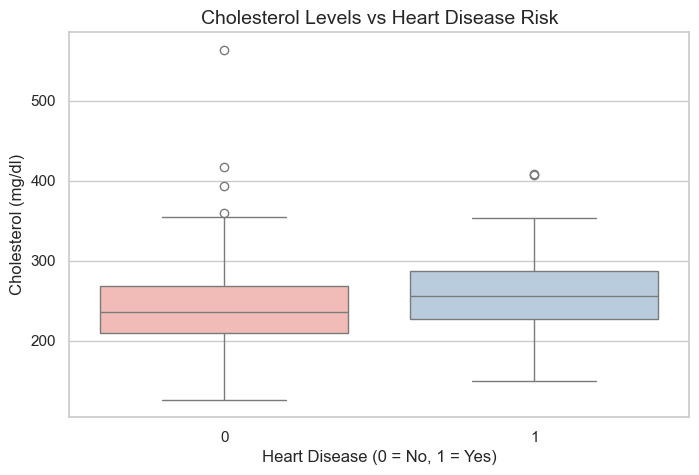

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='heart_disease', y='cholesterol', data=df, hue='heart_disease', palette='Pastel1', legend=False)

plt.title('Cholesterol Levels vs Heart Disease Risk', fontsize=14)
plt.xlabel('Heart Disease (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Cholesterol (mg/dl)', fontsize=12)
plt.show()

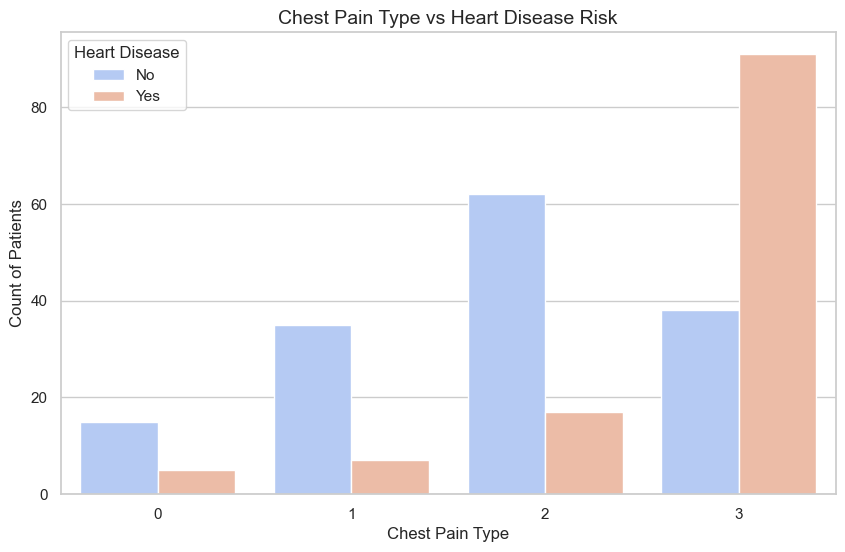

In [22]:
plt.figure(figsize=(10, 6))
sns.countplot(x='chest_pain_type', hue='heart_disease', data=df, palette='coolwarm')

plt.title('Chest Pain Type vs Heart Disease Risk', fontsize=14)
plt.xlabel('Chest Pain Type', fontsize=12)
plt.ylabel('Count of Patients', fontsize=12)
plt.legend(title='Heart Disease', labels=['No', 'Yes'])
plt.show()

In [ ]:
# categories: 0 typical angina, 1 atypical angina, 2 non- anginal pain, 3 asymptomatic (Nominal)
joo